In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

In [2]:
%matplotlib ipympl

In [3]:
from tqdm.auto import tqdm

import numpy as np
import matplotlib.pyplot as plt

from Simulate import *
from data_quartzsi import t_r_raw as t_r, A_r, A_s

In [4]:
# Simulate Reference pulse
def simulate_reference(L, deltat):
    
    toff=1.0e-11
    twidth=8.0e-13
    tdecay=1.0e-12
    scale=1.0e12
    x=np.zeros(L, float)
    for t in range(0,L):
        T=t*deltat - toff
        x[t]=-scale*T* np.exp(-(T/twidth)**2 - T/tdecay)

    return x

In [5]:
def rts(n0, nj, Dj):
    """
    Calculate reflection and transfer coeffs for individual layers.
    returns tuple of r, t and t**2 - r**2 for layer j.
    """

    c = np.cos(nj*Dj)
    s = np.sin(nj*Dj)
    d = c + (0.5j) * (nj/n0 + n0/nj) * s
    r = (0.5j) * s * (n0/nj - nj/n0) / d
    t = 1.0/d
    # note transmission coeff phase is relative to n0 and kD
    # s phase which is used to compute reflection coeff is relative to input
    return (r, t*np.exp((1J)*n0*Dj), t*t-r*r)


def RTm(m, n0, layers):
    """
    Apply rts across all layers.
    Reflection and Transmission coefficients for m layers.
    """
    U=0.0; V=1.0; T=1.0; R=0.0

    for j in range(0,m):
        nj = layers[j][0]
        Dj = layers[j][1]
        (r,t,s) = rts(n0, nj, Dj)
        Vlast = V
        (U,V) = (r*V + s*U, V - r*U)
        T = T * t * Vlast / V
        R = U/V

    return (R,T)


def simulate_parallel(x, layers, deltat, noise_level):
    L = len(x)
# convolution done with 4*L points
    M = 4 * L
    N = 8 * L
# wave number for frequency point k is k*dk
    deltaf = 1.0/(N*deltat)
    dk = 2 * np.pi * deltaf / 2.9979e8
    m = len(layers)
    indices = np.array([l[0] for l in layers])
    thicknesses = np.array([l[1] for l in layers])
    T = np.zeros(N, complex)

    for k in range(0,M+1):
        kD = k*dk*thicknesses
        nkD = np.array([(indices[l],kD[l]) for l in range(0,m)])

        T[k] = RTm(m, 1.0, nkD)[1]

    for k in range(1,M):
        T[N-k]=np.conjugate(T[k])

    z = np.zeros(N, float)
    z[0:L] = x[0:L]
    X = np.fft.fft(z)/N
    Y = T*X
    y = N * np.fft.ifft(Y).real + noise_level * np.random.randn(N)
    
    return (T,y)

In [6]:
simulate_data = False

In [7]:
if simulate_data:
    
    # Create Ref pulse
    deltat = 0.0194e-12
    L = 2**12

    noise_level = 0.002
    
    x_exp = simulate_reference(L, deltat)
    t_r = np.arange(0,L*deltat, deltat)
    
    
    or_params = {'n1': 1.9, 'k1': 0.008, 'd1': 0.980e-3, 
                 'n2': 3.5, 'k2': 0.005, 'd2': 0.400e-3}
    
    layers=[(or_params['n1'] - 1j*or_params['k1'], or_params['d1']),
            (or_params['n2'] - 1j*or_params['k2'], or_params['d2'])]

    (T, y) = simulate_parallel(x_exp, layers, deltat, noise_level)
    # truncate to L points
    true_x_exp = y[0:L]
    
else:
    
    or_params = None
    
    # Global Variables
    L = len(A_r)  # Match actual data length (2425)
    deltat = (t_r[1]-t_r[0])*1e-12  # Time step from data

    t_r = t_r - t_r[0]

    x_exp = A_r
    true_x_exp = A_s

In [8]:
def mae_loss(y_test, y_pred):
    return np.mean(np.abs(y_test - y_pred))

Initial loss: 0.038649581147489315


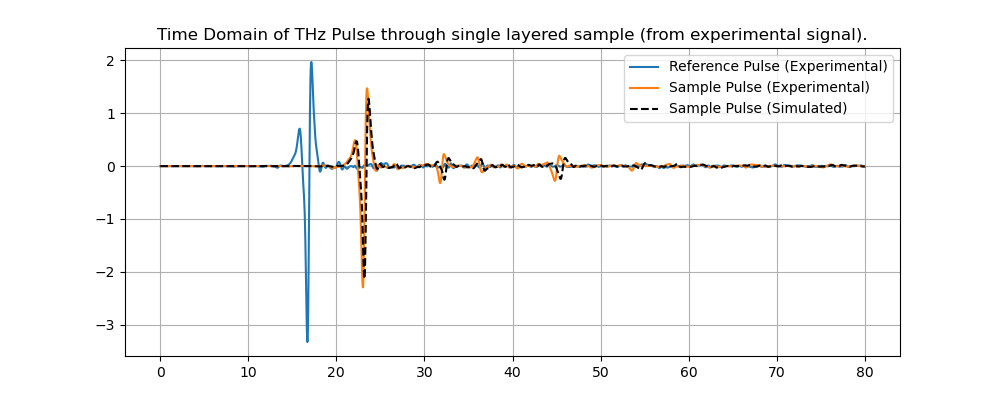

In [36]:
# Inintial simulation
n_init = [1.9820, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [  1e-3, 0.4e-3]

layers= [(n_init[i] - 1j*k_init[i], d_init[i]) for i in range(2)]

T_exp, y_exp = simulate_from_signal(x_exp, layers, deltat)
y_exp = y_exp[:L].detach().cpu().numpy()

initial_loss = mae_loss(true_x_exp, y_exp)
print(f"Initial loss: {initial_loss}")

plt.figure(figsize=(10,4))
plt.title('Time Domain of THz Pulse through single layered sample (from experimental signal).')

plt.plot(t_r, x_exp, label='Reference Pulse (Experimental)')
plt.plot(t_r, true_x_exp, label='Sample Pulse (Experimental)')
plt.plot(t_r, y_exp, label='Sample Pulse (Simulated)', color = 'black', linestyle = '--')

plt.legend()
plt.grid()
#plt.savefig("Quartzsi plots /Quartz plot.png")
plt.show()

### With optimizer

In [10]:
def log_cosh_loss(y_pred, y_test):
    # Log-Cosh(x) = log((exp(x) + exp(-x)) / 2)
    # A numerically stable version is:
    # log(cosh(x)) ≈ |x| + log(1 + exp(-2|x|)) - log(2)
    diff = y_pred - y_test
    return torch.mean(torch.log(torch.cosh(diff + 1e-12)))

In [11]:
def find_optimal_params(initial_guess = (n_init, k_init, d_init), n_iters = 50000, print_step = 1000):

    n10, k10, d10, n20, k20, d20 = n_init[0], k_init[0], d_init[0], n_init[1], k_init[1], d_init[1]

    n1 = torch.tensor(1.0, requires_grad = True)
    k1 = torch.tensor(1.0, requires_grad = True)
    d1 = torch.tensor(1.0, requires_grad = True)
    n2 = torch.tensor(1.0, requires_grad = True)
    k2 = torch.tensor(1.0, requires_grad = True)
    d2 = torch.tensor(1.0, requires_grad = True)

#     k1 = torch.tensor(0.0, requires_grad = False)
#     k2 = torch.tensor(0.0, requires_grad = False)

    n1s, k1s, d1s  = [n1.clone().detach()*n10], [k1.clone().detach()*k10], [d1.clone().detach()*d10]
    n2s, k2s, d2s  = [n2.clone().detach()*n20], [k2.clone().detach()*k20], [d2.clone().detach()*d20]

    true_x_exp_tens = torch.tensor(true_x_exp, requires_grad=False)

    learning_rate = 1e-4
    optimizer = torch.optim.Adam([n1, k1, d1, n2, k2, d2], lr=learning_rate)

    layers = [(n1*n10 - 1j*k1*k10, d1*d10), (n2*n20 - 1j*k2*k20, d2*d20)]
    T_exp, y_exp = simulate_from_signal(x_exp, layers, deltat)

    loss = (true_x_exp_tens - y_exp[:L]).abs().mean() +  log_cosh_loss(true_x_exp_tens, y_exp[:L])
    
    losses = [loss.clone().detach()]
    
    print(f"Epoch={1:6d}, n1={n1.item()*n10:2e}, k1={k1.item()*k10:2e}, d1={d1.item()*d10:2e} - n2={n2.item()*n20:2e}, k2={k2.item()*k20:2e}, d2={d2.item()*d20:2e} - Loss={loss.item():2e}")
    
    for i_iter in range(1, n_iters):

#         if i_iter > 5000:
#             k1.requires_grad = True
#             k2.requires_grad = True
            
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()
        
        layers = [(n1*n10 - 1j*k1*k10, d1*d10), (n2*n20 - 1j*k2*k20, d2*d20)]

        T_exp, y_exp = simulate_from_signal(x_exp, layers, deltat)

        loss = (true_x_exp_tens - y_exp[:L]).abs().mean() + log_cosh_loss(true_x_exp_tens, y_exp[:L])

        with torch.no_grad():

            losses.append(loss.clone().detach())

            if i_iter in [n_iters - 1] or (i_iter + 1)%print_step == 0:
                lr = optimizer.param_groups[0]["lr"]
                print(f"Epoch={i_iter+1:6d}, n1={n1.item()*n10:2e}, k1={k1.item()*k10:2e}, d1={d1.item()*d10:2e} - n2={n2.item()*n20:2e}, k2={k2.item()*k20:2e}, d2={d2.item()*d20:2e} - Loss={loss.item():2e}")

            n1s.append(n1.clone().detach()*n10)
            k1s.append(k1.clone().detach()*k10)
            d1s.append(d1.clone().detach()*d10)

            n2s.append(n2.clone().detach()*n20)
            k2s.append(k2.clone().detach()*k20)
            d2s.append(d2.clone().detach()*d20)

    # Plot history
    fig = plt.figure(figsize=(12, 4))
    plt.title("Optimization process")
    plt.plot(losses[1:])
    plt.ylabel('Loss')
    plt.xlabel('Iteration')
    plt.yscale('log')
    plt.show()

    return np.array([n1s, k1s, d1s, n2s, k2s, d2s, losses])

In [12]:
def nkds_from_trajectory(trajectory):
    best_params = trajectory.T[-1][:-1].reshape(2,3).T
    labels = ['n', 'k', 'd']
    for i, vs in enumerate(best_params):
        print(f"{labels[i]}_init = [{', '.join([f'{v:6f}' for v in vs])}]")
    print()
    print(f"Loss: {trajectory.T[-1][-1]}")
    return best_params

In [13]:
def plot_pulses(ns, ks, ds):

    layers_try = [(ns[i] - 1j*ks[i], ds[i]) for i in range(2)]

    T_exp_try, y_exp_try = simulate_from_signal(x_exp, layers_try, deltat)

    y_exp_try = y_exp_try[:L].detach().cpu().numpy()

    fig = plt.figure(figsize=(8, 4))
    plt.title('Time Domain of THz Pulse through single layered sample (from experimental signal).')
    plt.plot(true_x_exp, label = 'Sample Pulse (Experimental)', color = 'C1')
    plt.plot(y_exp_try, label = 'Best modified (Simulated)', color = 'black', alpha = 0.75, linestyle = '--')
    plt.legend()
    plt.grid()
    #plt.savefig("Quartzsi plots /Quartz plot.png")
    plt.show()

In [14]:
n_iters = 50000

Epoch=     1, n1=1.982000e+00, k1=7.100000e-03, d1=1.000000e-03 - n2=3.400000e+00, k2=5.400000e-03, d2=4.000000e-04 - Loss=4.659777e-02
Epoch=  1000, n1=1.982185e+00, k1=6.405162e-03, d1=9.851821e-04 - n2=3.359885e+00, k2=4.875391e-03, d2=3.913508e-04 - Loss=6.045515e-03
Epoch=  2000, n1=1.983004e+00, k1=5.702281e-03, d1=9.847094e-04 - n2=3.364276e+00, k2=4.334797e-03, d2=3.907277e-04 - Loss=5.535325e-03
Epoch=  3000, n1=1.981576e+00, k1=5.082356e-03, d1=9.853675e-04 - n2=3.374401e+00, k2=3.850735e-03, d2=3.895645e-04 - Loss=5.155915e-03
Epoch=  4000, n1=1.977305e+00, k1=4.497609e-03, d1=9.875398e-04 - n2=3.392753e+00, k2=3.382858e-03, d2=3.874818e-04 - Loss=4.836268e-03
Epoch=  5000, n1=1.969475e+00, k1=4.079807e-03, d1=9.914601e-04 - n2=3.421879e+00, k2=2.985662e-03, d2=3.842759e-04 - Loss=4.640973e-03
Epoch=  6000, n1=1.962756e+00, k1=3.945114e-03, d1=9.949734e-04 - n2=3.452658e+00, k2=2.708265e-03, d2=3.807627e-04 - Loss=4.564571e-03
Epoch=  7000, n1=1.957969e+00, k1=3.911797e-03, 

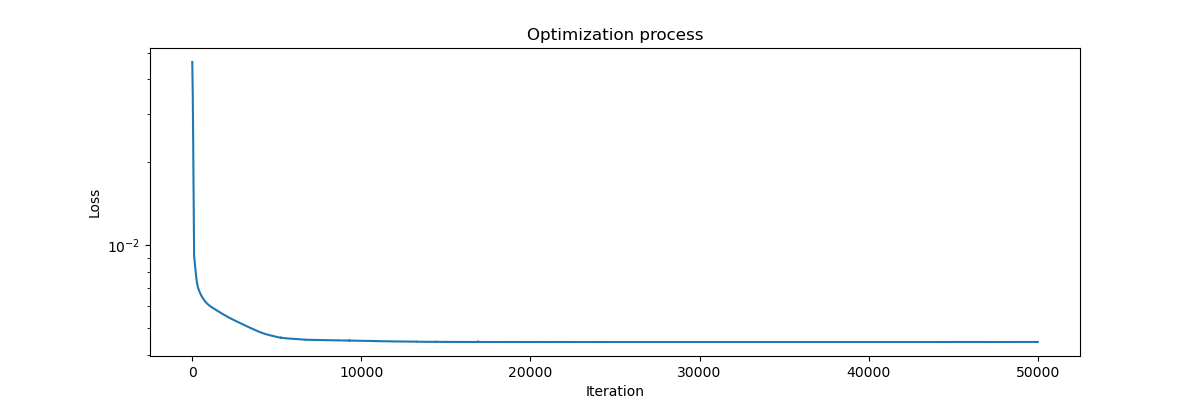

In [15]:
# Inintial simulation
n_init = [1.9820, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [  1e-3, 0.4e-3]

trajectory1 = find_optimal_params(initial_guess = (n_init, k_init, d_init), n_iters=n_iters)

Epoch=     1, n1=1.900000e+00, k1=7.100000e-03, d1=9.000000e-04 - n2=3.400000e+00, k2=5.400000e-03, d2=4.000000e-04 - Loss=7.385978e-02
Epoch=  1000, n1=1.954479e+00, k1=7.144339e-03, d1=9.446275e-04 - n2=3.431396e+00, k2=5.546911e-03, d2=4.078385e-04 - Loss=2.101296e-02
Epoch=  2000, n1=1.990433e+00, k1=6.194231e-03, d1=9.809801e-04 - n2=3.331008e+00, k2=4.867426e-03, d2=3.946137e-04 - Loss=5.953845e-03
Epoch=  3000, n1=1.988868e+00, k1=5.435190e-03, d1=9.818197e-04 - n2=3.341249e+00, k2=4.278831e-03, d2=3.934262e-04 - Loss=5.442849e-03
Epoch=  4000, n1=1.984865e+00, k1=4.799780e-03, d1=9.837622e-04 - n2=3.361763e+00, k2=3.780404e-03, d2=3.910011e-04 - Loss=5.064253e-03
Epoch=  5000, n1=1.975787e+00, k1=4.260362e-03, d1=9.883122e-04 - n2=3.394240e+00, k2=3.331061e-03, d2=3.873837e-04 - Loss=4.766071e-03
Epoch=  6000, n1=1.966751e+00, k1=3.962432e-03, d1=9.928530e-04 - n2=3.434052e+00, k2=2.980396e-03, d2=3.828943e-04 - Loss=4.609244e-03
Epoch=  7000, n1=1.960228e+00, k1=3.875262e-03, 

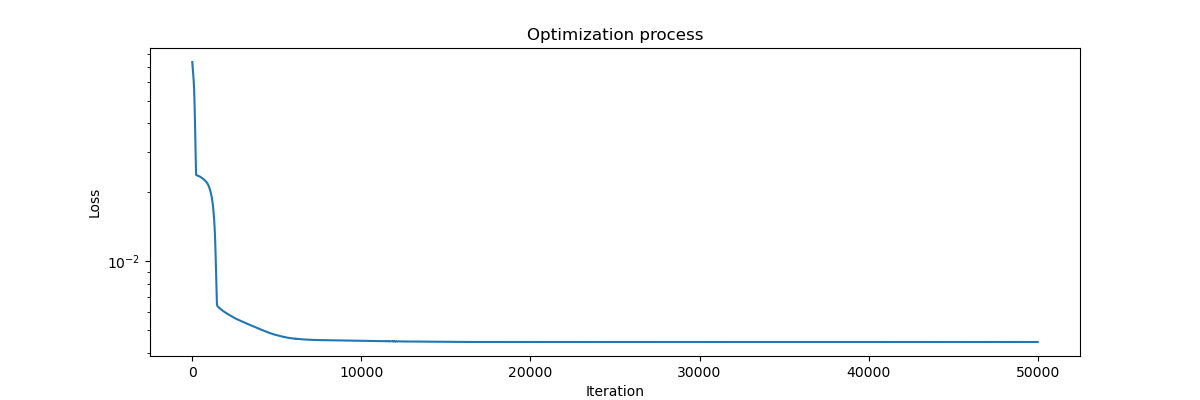

In [16]:
# Inintial simulation
n_init = [1.90, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [ 900.0e-6, 0.4e-3]

trajectory2 = find_optimal_params(initial_guess = (n_init, k_init, d_init), n_iters=n_iters)

Epoch=     1, n1=2.010000e+00, k1=7.100000e-03, d1=9.000000e-04 - n2=3.400000e+00, k2=5.400000e-03, d2=4.000000e-04 - Loss=3.038853e-02
Epoch=  1000, n1=2.013099e+00, k1=6.410859e-03, d1=9.684129e-04 - n2=3.276409e+00, k2=4.873424e-03, d2=4.007828e-04 - Loss=6.438714e-03
Epoch=  2000, n1=2.002811e+00, k1=5.473869e-03, d1=9.749939e-04 - n2=3.285873e+00, k2=4.173152e-03, d2=3.999939e-04 - Loss=5.572500e-03
Epoch=  3000, n1=1.994381e+00, k1=4.798402e-03, d1=9.791041e-04 - n2=3.320935e+00, k2=3.650234e-03, d2=3.957930e-04 - Loss=5.145536e-03
Epoch=  4000, n1=1.980057e+00, k1=4.275588e-03, d1=9.861951e-04 - n2=3.375966e+00, k2=3.212414e-03, d2=3.894957e-04 - Loss=4.801321e-03
Epoch=  5000, n1=1.967981e+00, k1=4.021522e-03, d1=9.922109e-04 - n2=3.427654e+00, k2=2.869153e-03, d2=3.836244e-04 - Loss=4.616547e-03
Epoch=  6000, n1=1.960281e+00, k1=3.930904e-03, d1=9.962150e-04 - n2=3.464138e+00, k2=2.558773e-03, d2=3.795055e-04 - Loss=4.544845e-03
Epoch=  7000, n1=1.957062e+00, k1=3.946768e-03, 

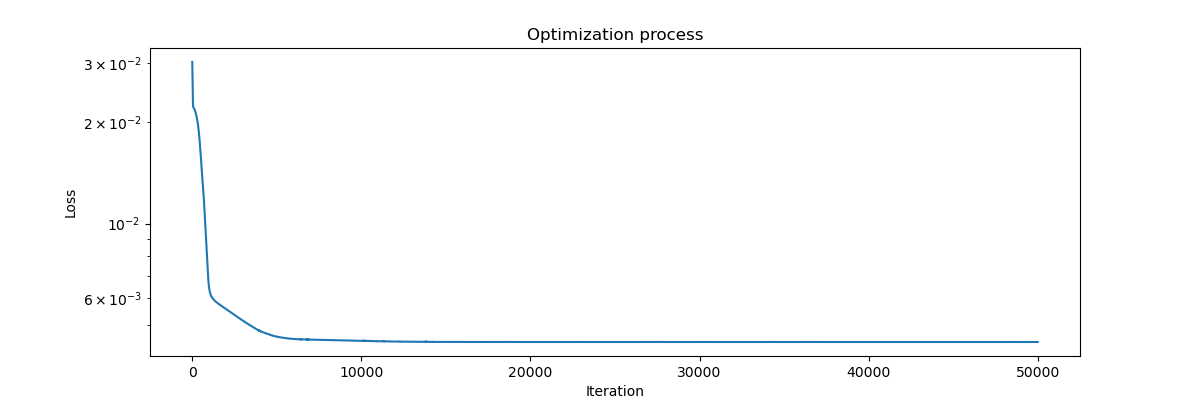

In [17]:
# Inintial simulation
n_init = [2.01, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [ 900.0e-6, 0.4e-3]

trajectory3 = find_optimal_params(initial_guess = (n_init, k_init, d_init), n_iters=n_iters)

In [18]:
# # Inintial simulation
# n_init = [1.70, 3.6000]
# k_init = [0.0011, 0.00254]
# d_init = [ 200.0e-6, 0.1e-3]

# trajectory4 = find_optimal_params(initial_guess = (n_init, k_init, d_init), n_iters=n_iters)

In [19]:
trajectories = [trajectory1, trajectory2, trajectory3] #, trajectory4]

Trajectory: 1

n_init = [1.963971, 3.446801]
k_init = [0.005410, -0.001482]
d_init = [0.000994, 0.000381]

Loss: 0.004452827100836386


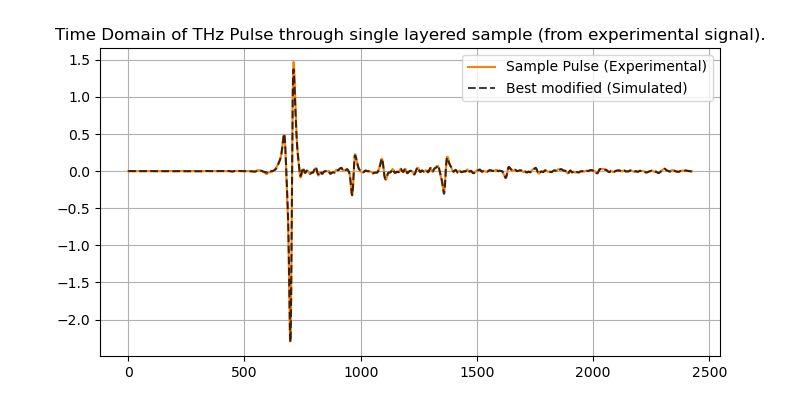

Trajectory: 2

n_init = [1.964020, 3.446895]
k_init = [0.005409, -0.001482]
d_init = [0.000994, 0.000381]

Loss: 0.004451751033473435


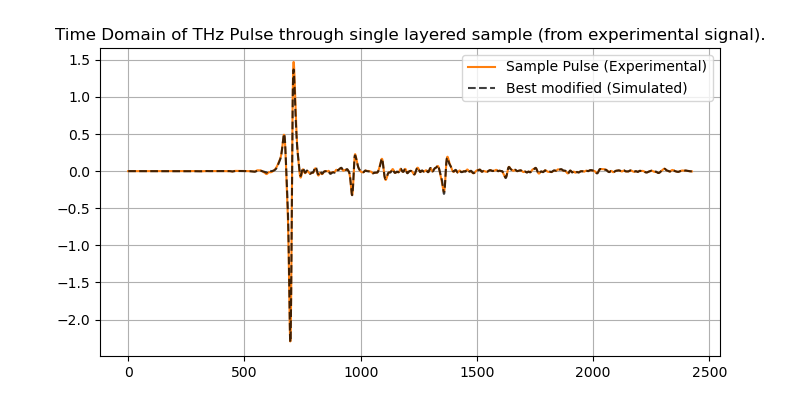

Trajectory: 3

n_init = [1.964028, 3.446896]
k_init = [0.005410, -0.001483]
d_init = [0.000994, 0.000381]

Loss: 0.0044517332971286015


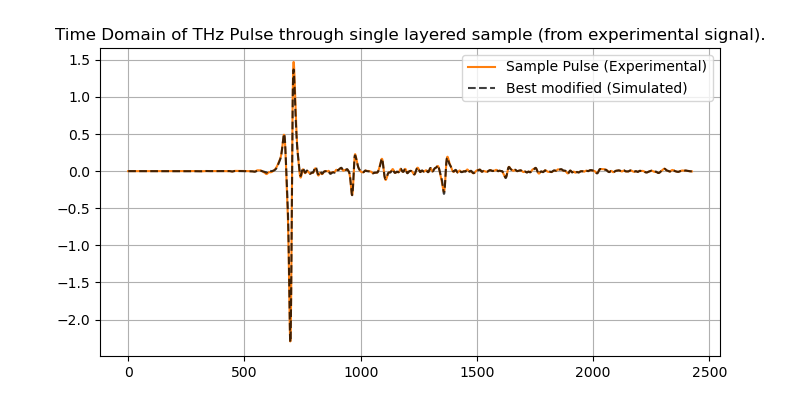

In [20]:
for i, traj in enumerate(trajectories):
    print(f"Trajectory: {i+1}\n")
    traj_ns, traj_ks, traj_ds = nkds_from_trajectory(traj)
    plot_pulses(traj_ns, traj_ks, traj_ds)

In [21]:
inds = {'n1': 0, 'k1': 1, 'd1': 2, 'n2': 3, 'k2': 4, 'd2': 5}

In [22]:
def calculate_3d_loss_landscape(x, y, x_iter = 100, y_iter = 100, pm = 0.5, original_params = None):
    loss_landscape = []

    if original_params is None:
        min_loss_traj = np.inf
        best_traj = 0
        for i, traj in enumerate(trajectories):
            if traj[-1][-1] < min_loss_traj:
                best_pars = traj.T[-1][:-1]
                best_traj = i
                min_loss_traj = traj[-1][-1]

        vs = {k:best_pars[v] for k,v in inds.items()}
    else:
        vs = original_params.copy()
        
    xs = np.linspace((1-pm)*vs[x], (1+pm)*vs[x], x_iter)
    ys = np.linspace((1-pm)*vs[y], (1+pm)*vs[y], y_iter)
    
    for xi in xs:
        for yi in ys:
            vs[x], vs[y] = xi, yi

            layers_try = [(vs['n1'] - 1j*vs['k1'], vs['d1']),
                          (vs['n2'] - 1j*vs['k2'], vs['d2'])]

            T_exp_try, y_exp_try = simulate_from_signal(x_exp, layers_try, deltat)
            y_exp_try = y_exp_try[:L]  #.detach().cpu().numpy()
            loss = log_cosh_loss(y_exp_try.detach(), true_x_exp)
#             loss = mae_loss(true_x_exp, y_exp_try)
            loss_landscape.append(loss)  

    X, Y = np.meshgrid(xs, ys)
    return X, Y, np.array(loss_landscape).reshape(x_iter, y_iter)

In [23]:
def plot_3d_loss_landscape_and_trajectories(x, y, X, Y, loss_land, res = 200):

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(projection='3d')

    ax.plot_surface(X, Y, loss_land, cmap='terrain', alpha=0.6, antialiased=True, linewidth=0, rcount=res, ccount=res)

    for i, traj in enumerate(trajectories):
        ax.scatter(traj[inds[x]], traj[inds[y]], traj[-1], marker='.', color = f"C{i}", s = 0.1, label = f"Trajectory {i+1}")
        ax.scatter(traj[inds[x]][-1], traj[inds[y]][-1], traj[-1][-1], marker='*', color = f"C{i}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_zlabel('loss')
    plt.legend()
    plt.show()

In [24]:
X, Y, loss_landscape = {}, {}, {}

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


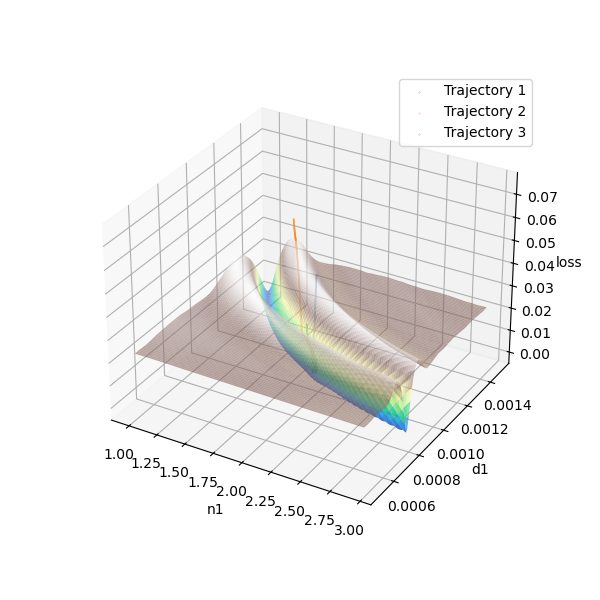

In [25]:
x, y = 'n1', 'd1'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('n1', 'd1', X['n1'], Y['d1'], loss_landscape['n1-d1'])

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


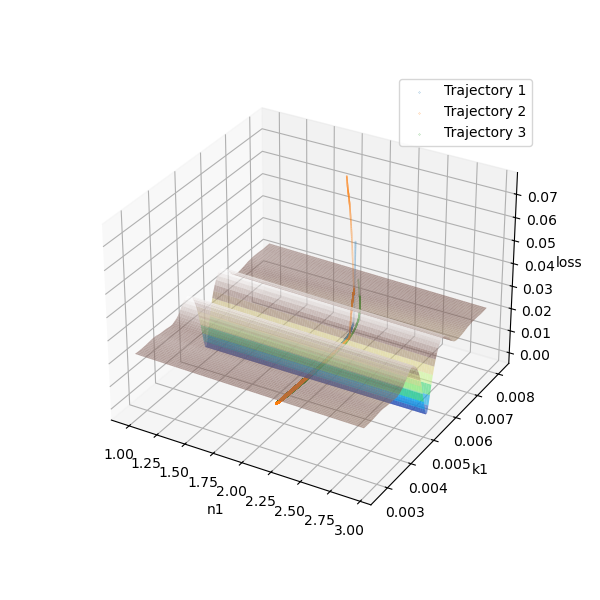

In [26]:
x, y = 'n1', 'k1'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('n1', 'k1', X['n1'], Y['k1'], loss_landscape['n1-k1'])

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


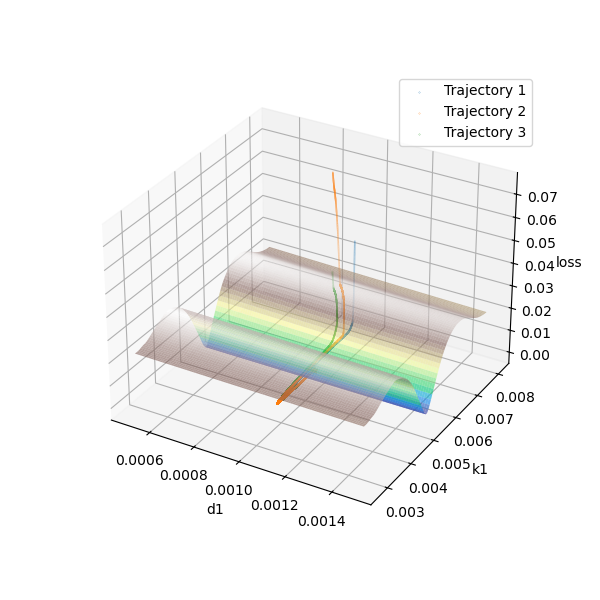

In [27]:
x, y = 'd1', 'k1'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('d1', 'k1', X['d1'], Y['k1'], loss_landscape['d1-k1'])

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


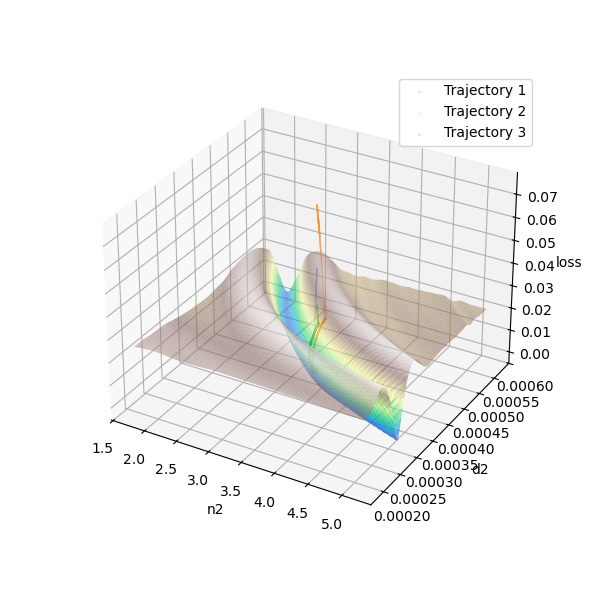

In [28]:
x, y = 'n2', 'd2'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('n2', 'd2', X['n2'], Y['d2'], loss_landscape['n2-d2'])

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


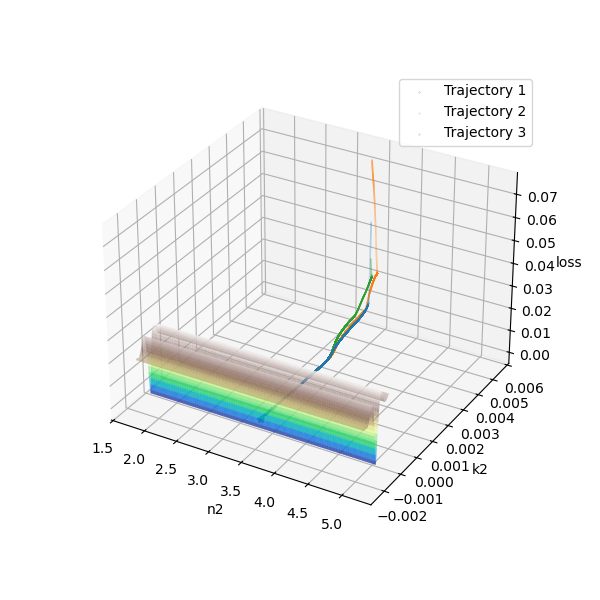

In [29]:
x, y = 'n2', 'k2'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('n2', 'k2', X['n2'], Y['k2'], loss_landscape['n2-k2'])

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_34945/3638492084.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = y_pred - y_test


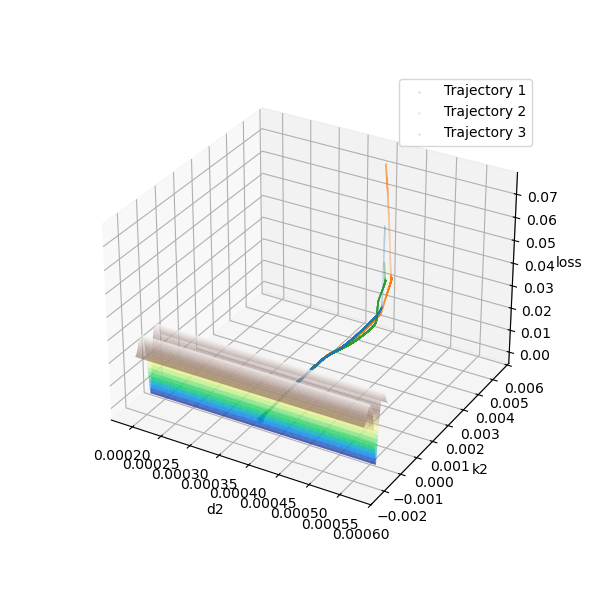

In [30]:
x, y = 'd2', 'k2'
X[x], Y[y], loss_landscape[f'{x}-{y}'] = calculate_3d_loss_landscape(x, y, original_params = or_params)

plot_3d_loss_landscape_and_trajectories('d2', 'k2', X['d2'], Y['k2'], loss_landscape['d2-k2'])

In [31]:
def plot_axis(ax, x, y, X, Y, loss_land):
    ax.contourf(X, Y, loss_land, cmap='viridis')

    for i, traj in enumerate(trajectories):
        ax.scatter(traj[inds[x]], traj[inds[y]], marker='.', label = f"Trajectory {i+1}")

    ax.set_xlabel(x)
    ax.set_ylabel(y)

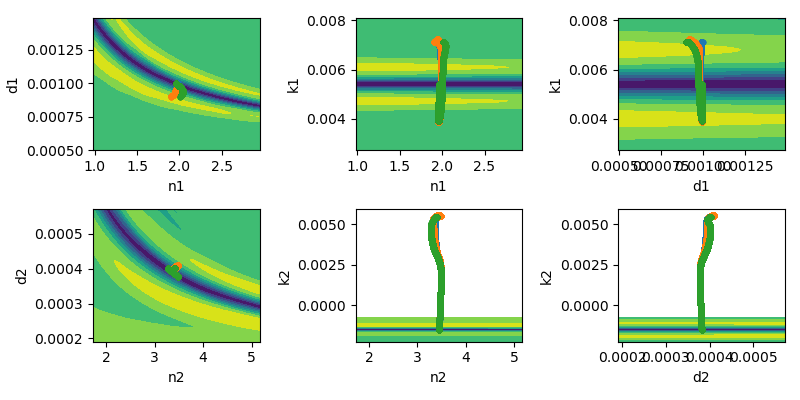

In [32]:
fig, ax = plt.subplots(2, 3, figsize=(8,4))

plot_axis(ax[0,0], 'n1', 'd1', X['n1'], Y['d1'], loss_landscape['n1-d1'])
plot_axis(ax[0,1], 'n1', 'k1', X['n1'], Y['k1'], loss_landscape['n1-k1'])
plot_axis(ax[0,2], 'd1', 'k1', X['d1'], Y['k1'], loss_landscape['d1-k1'])
plot_axis(ax[1,0], 'n2', 'd2', X['n2'], Y['d2'], loss_landscape['n2-d2'])
plot_axis(ax[1,1], 'n2', 'k2', X['n2'], Y['k2'], loss_landscape['n2-k2'])
plot_axis(ax[1,2], 'd2', 'k2', X['d2'], Y['k2'], loss_landscape['d2-k2'])

plt.tight_layout()
plt.show()

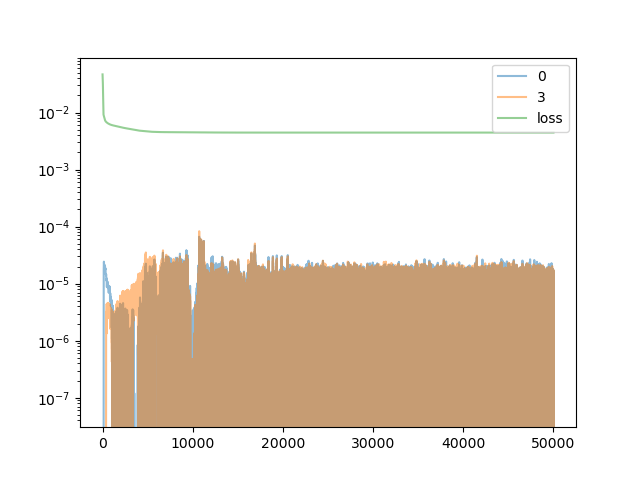

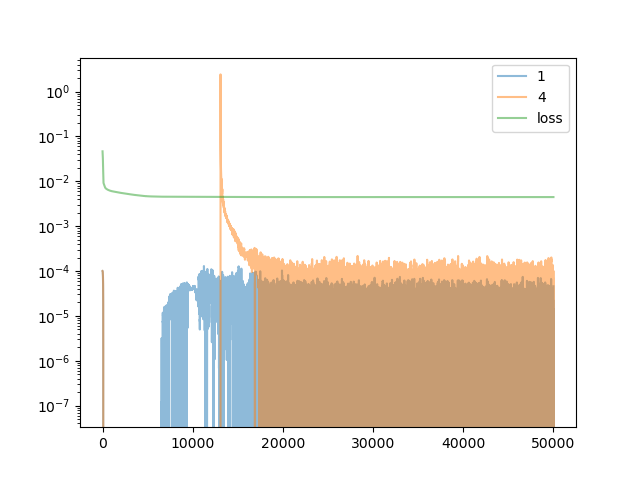

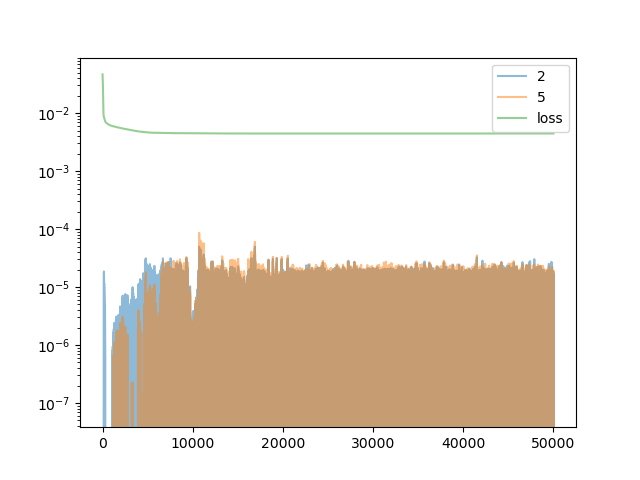

In [33]:
for j in range(3):
    fig = plt.figure()
    for i in range(j,6,3):
        plt.plot(np.diff(trajectory1[i])/trajectory1[i][1:], label=i, alpha=0.5)
    plt.plot(trajectory1[-1], label='loss', alpha=0.5)
    plt.yscale('log')
    plt.legend()
    plt.show()

In [34]:
# res = 200 

# fig, ax = plt.subplots(1, 3, subplot_kw={'projection': '3d'}, figsize=(8, 5))

# ax[0].plot_surface(nX, dY, n1_d1_loss.reshape(n_iter, d_iter), cmap='terrain', alpha=0.6,
#                 antialiased=True, linewidth=0, rcount=res, ccount=res)
# ax[0].scatter(n1s, d1s, losses, marker='.', color ='red')
# ax[0].set_xlabel('n1')
# ax[0].set_ylabel('d1')
# ax[0].set_zlabel('loss')

# ax[1].plot_surface(nX, kY, n1_k1_loss.reshape(n_iter, k_iter), cmap='terrain', alpha=0.6,
#                 antialiased=True, linewidth=0, rcount=res, ccount=res)
# ax[1].scatter(n1s, k1s, losses, marker='.', color ='red')
# ax[1].set_xlabel('n1')
# ax[1].set_ylabel('k1')
# ax[1].set_zlabel('loss')

# ax[2].plot_surface(kX, dY, k1_d1_loss.reshape(k_iter, d_iter), cmap='terrain', alpha=0.6,
#                 antialiased=True, linewidth=0, rcount=res, ccount=res)
# ax[2].scatter(k1s, d1s, losses, marker='.', color ='red')
# ax[2].set_xlabel('k1')
# ax[2].set_ylabel('d1')
# ax[2].set_zlabel('loss')

# plt.tight_layout()
# plt.show()

In [35]:
# fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(8,3))
# ax1.contourf(nX, dY, n1_d1_loss.reshape(n_iter, d_iter), cmap='viridis') # Standard 2D filled contour
# ax1.plot(n1s, d1s, 'r')

# ax2.contourf(nX, kY, n1_k1_loss.reshape(n_iter, k_iter), cmap='viridis') # Standard 2D filled contour
# ax2.plot(n1s, k1s, 'r')

# ax3.contourf(kX, dY, k1_d1_loss.reshape(k_iter, d_iter), cmap='viridis') # Standard 2D filled contour
# ax3.plot(k1s, d1s, 'r')

# plt.tight_layout()
# plt.show()